# Bayesian Quantum Phase Estimation (QPE) — Qiskit notebook

**Primitive:** Single-ancilla, adaptive **Bayesian Quantum Phase Estimation** (a.k.a.
iterative / Kitaev-style QPE with a classical Bayesian posterior update), as opposed to
the textbook QFT-based QPE. This is topic **3) Bayesian QPE** in the phase-estimation
series, using the same matched-notebook workflow as the earlier chapters.

## Why Bayesian QPE is structured differently from a fixed circuit
Standard QFT-based QPE is a single, fixed circuit whose output histogram directly
encodes the phase. Bayesian QPE instead runs **many small 2-qubit "Ramsey" experiments**
in sequence, each with an adaptively chosen power `M_m` and phase offset `beta_m`, and
updates a classical probability distribution ("posterior") over the unknown phase after
every single-shot measurement. There is no QFT step at all. Because of this, the 14-cell
template from the shared spec is followed as closely as possible, with one extra cell
inserted for the adaptive estimation loop itself (this is noted at each step below).

## SETUP (identical in both notebooks — do not diverge)
- **N_QUBITS = 2** — `q0` = ancilla / probe qubit (measured every round), `q1` = system
  qubit, held in the eigenstate `|1>` of the unitary being estimated.
- **Unitary under test:** `U = P(THETA_TRUE)`, the 1-qubit phase gate
  `diag(1, e^{i·THETA_TRUE})`, with eigenstate `|1>` and eigenvalue `e^{i·THETA_TRUE}`.
- **THETA_TRUE_FRAC = 0.372** (i.e. `THETA_TRUE = 2π·0.372` rad) — deliberately **not**
  a dyadic fraction, to demonstrate that (unlike QFT-QPE) Bayesian QPE is not restricted
  to phases with a finite binary expansion.
- **Gate sequence per round** (parameterized by `M_m`, `beta_m`):
  `X(q1)` (state prep) → `H(q0)` → controlled-`P(M_m·THETA_TRUE)` from `q0` to `q1`
  (this *is* controlled-`U^{M_m}`, since powers of a diagonal phase gate just add angles)
  → `P(beta_m)` on `q0` → `H(q0)` → measure `q0`.
- **SHOTS = 8000**, **SEED = 42** (used both for the shot-based validation circuit and,
  critically, to seed the *classical* RNG that drives the adaptive Bayesian loop itself
  — see the note below).
- **ROUNDS = 25** adaptive rounds, each consisting of one "cosine" experiment and one
  "sine"/quadrature experiment (50 single-shot measurements total).
- **GRID_N = 4000** points on the posterior grid over `theta ∈ [0, 2π)`.
- **M_MAX = 64** — cap on the exponentially growing power schedule `M_m = min(2^(m-1), M_MAX)`.
- **QUBIT ORDERING CONTRACT:** qubit 0 = rightmost bit in every printed bitstring
  (Qiskit's native convention — no reversal needed in this notebook; the CUDA-Q notebook
  performs an explicit reversal to match).
- **GLOBAL PHASE CONVENTION:** normalize so the first nonzero amplitude, in ascending
  bitstring order, is rotated to be real and positive.
- **Basis ordering for matrices:** `{|00>, |01>, |10>, |11>}`, ascending binary order.

## Theory recap
For a single Ramsey-type round with control power `M` and phase offset `beta`, starting
the ancilla in `|0>` and the system in the eigenstate `|1>` of `U = P(THETA_TRUE)`:

```
P(ancilla = 0 | theta) = (1 + cos(M*theta + beta)) / 2
P(ancilla = 1 | theta) = (1 - cos(M*theta + beta)) / 2
```

Given a measured outcome `d`, Bayes' rule updates the posterior over `theta` on a grid:
`posterior(theta) ∝ prior(theta) · P(d | theta, M, beta)`. The **adaptive** part chooses
`beta_m = -M_m · mu_{m-1}` (where `mu_{m-1}` is the current posterior circular mean) so
each new experiment's fringe is centered on the current best guess — this is what makes
the scheme converge in `O(ROUNDS)` experiments instead of needing exponentially many
shots. A pure cosine fringe is symmetric under reflection about `mu`, so a matching
**sine** ("quadrature", `beta_m + π/2`) experiment is run every round as well to resolve
the left/right sign ambiguity a cosine-only scheme would leave.

## ⚠ Randomness note (read before running)
Aer's internal PRNG and CUDA-Q's internal PRNG are **different implementations** — same
`SEED` does **not** produce the same measurement outcomes between the two frameworks. To
keep the two notebooks' Bayesian trajectories numerically matched, the adaptive loop in
both notebooks computes the *exact* round-outcome probability from each framework's own
statevector simulation, then draws the actual 0/1 outcome from a **single shared
`numpy` RNG seeded with `SEED`**. Only the later shot-based *validation* cell uses each
framework's native sampler (Aer here, `cudaq.sample` in the other notebook) — that cell
is not expected to match bit-for-bit, only in aggregate statistics.

**Run all cells top to bottom.**


In [1]:
# Install Qiskit + Aer simulator backend + drawing dependency.
# Exact package names on PyPI: `qiskit` (core, tested against the 1.x API used below) and
# `qiskit-aer` (separate package providing AerSimulator). `pylatexenc` silences a warning
# when using circuit.draw(output="mpl").
!pip install -q qiskit qiskit-aer pylatexenc


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 7.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 60.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 48.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 1.4 MB/s eta 0:00:00


In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator

# ---- SETUP (must be identical to the CUDA-Q notebook) ----
N_QUBITS        = 2                 # q0 = ancilla ("probe"), q1 = system qubit (holds the eigenstate)
THETA_TRUE_FRAC = 0.372             # true eigenphase as a fraction of 2*pi (deliberately non-dyadic)
THETA_TRUE      = 2 * np.pi * THETA_TRUE_FRAC
SHOTS           = 8000
SEED            = 42
ROUNDS          = 25                # each round = 1 cosine + 1 sine single-shot experiment
GRID_N          = 4000              # resolution of the posterior grid over theta in [0, 2*pi)
M_MAX           = 64                # cap on the U-power growth schedule 2**(m-1)

print(f"N_QUBITS={N_QUBITS}  THETA_TRUE={THETA_TRUE:.6f} rad (frac={THETA_TRUE_FRAC})")
print(f"SHOTS={SHOTS}  SEED={SEED}  ROUNDS={ROUNDS}  GRID_N={GRID_N}  M_MAX={M_MAX}")


N_QUBITS=2  THETA_TRUE=2.337345 rad (frac=0.372)
SHOTS=8000  SEED=42  ROUNDS=25  GRID_N=4000  M_MAX=64


In [3]:
def ramsey_round_circuit(M_m: int, beta_m: float) -> QuantumCircuit:
    '''
    One Ramsey-type experiment of Bayesian QPE (WITH measurement, for shot-based runs).
      q0 = ancilla probe qubit (measured)
      q1 = system qubit, prepared in |1>, the eigenstate of U = P(THETA_TRUE)
    '''
    qc = QuantumCircuit(N_QUBITS, 1, name=f"round_M{M_m}")

    # 1) Prepare the system qubit in the eigenstate |1> of U
    qc.x(1)

    # 2) Put the ancilla in an equal superposition (Ramsey "first pulse")
    qc.h(0)

    # 3) Controlled-U^{M_m}. Since U = P(THETA_TRUE) is diagonal, U^{M_m} = P(M_m*THETA_TRUE)
    #    (repeated applications of a phase gate just add their angles), so a single controlled
    #    phase gate with the accumulated angle is used instead of M_m separate CP gates.
    qc.cp(M_m * THETA_TRUE, 0, 1)

    # 4) Adaptive phase correction: rotate the ancilla's phase reference by beta_m before the
    #    final Hadamard -- this is what "aims" the Ramsey fringe at the current best guess.
    qc.p(beta_m, 0)

    # 5) Second Ramsey pulse converts phase information into a measurable population
    qc.h(0)

    # 6) Measure only the ancilla; system qubit is discarded each round
    qc.measure(0, 0)
    return qc


def ramsey_round_unitary_circuit(M_m: int, beta_m: float) -> QuantumCircuit:
    '''Same as above but WITHOUT measurement, for exact statevector / Operator extraction.'''
    qc = QuantumCircuit(N_QUBITS, name=f"round_M{M_m}_unitary")
    qc.x(1)
    qc.h(0)
    qc.cp(M_m * THETA_TRUE, 0, 1)
    qc.p(beta_m, 0)
    qc.h(0)
    return qc


# sanity check on a representative round
M_demo, beta_demo = 1, 0.3
print(ramsey_round_circuit(M_demo, beta_demo))


     ┌───┐            ┌────────┐┌───┐┌─┐
q_0: ┤ H ├─■──────────┤ P(0.3) ├┤ H ├┤M├
     ├───┤ │P(2.3373) └────────┘└───┘└╥┘
q_1: ┤ X ├─■──────────────────────────╫─
     └───┘                            ║ 
c: 1/═════════════════════════════════╩═
                                      0 


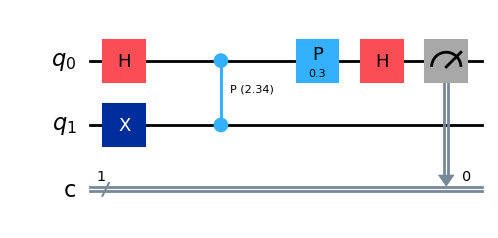

In [4]:
demo_circuit = ramsey_round_circuit(M_demo, beta_demo)
fig = demo_circuit.draw(output="mpl", style={"name": "iqp"})
fig.savefig("bayesian_qpe_qiskit_circuit.png", bbox_inches="tight", dpi=150)
fig


In [5]:
# Build the 2-qubit "core" unitary (H - controlled-P - P - H, EXCLUDING the fixed X(1) state
# prep) two independent ways and cross-check them before using either downstream.

I2 = np.eye(2)
H  = (1 / np.sqrt(2)) * np.array([[1, 1], [1, -1]])
def Pgate(phi):
    return np.array([[1, 0], [0, np.exp(1j * phi)]])

# (a) Hand-built matrix. Qiskit is little-endian: qubit 0 is the LEAST significant tensor
#     factor, so for 2 qubits the full matrix for an operator on q1 alone is kron(op_q1, I2)
#     and for an operator on q0 alone it is kron(I2, op_q0).
H_on_q0  = np.kron(I2, H)                                              # h(0)
P_on_q0  = np.kron(I2, Pgate(beta_demo))                                # p(beta_demo, 0)
CP_gate  = np.diag([1, 1, 1, np.exp(1j * M_demo * THETA_TRUE)])         # cp(M_demo*THETA_TRUE, 0, 1)
                                                                          # (diagonal depends only on
                                                                          # BOTH qubits being |1>, so
                                                                          # it is identical in either
                                                                          # bit-order convention)
core_hand = H_on_q0 @ P_on_q0 @ CP_gate @ H_on_q0     # rightmost operator = first gate applied

# (b) Qiskit's own operator extraction, on the SAME core (no X(1) prep) sub-circuit.
core_qc = QuantumCircuit(N_QUBITS)
core_qc.h(0)
core_qc.cp(M_demo * THETA_TRUE, 0, 1)
core_qc.p(beta_demo, 0)
core_qc.h(0)
core_qiskit = Operator(core_qc).data

print("Hand-built core matrix (little-endian, basis |q1 q0>):")
print(np.round(core_hand, 4))
print("\nQiskit Operator() extraction:")
print(np.round(core_qiskit, 4))

max_diff = np.max(np.abs(core_hand - core_qiskit))
print("\nMax abs difference:", max_diff)
assert max_diff < 1e-9, "hand-built and Qiskit-extracted matrices disagree!"
print("MATCH -- both constructions agree to floating-point precision.")


Hand-built core matrix (little-endian, basis |q1 q0>):
[[0.9777+0.1478j 0.0223-0.1478j 0.    +0.j     0.    +0.j    ]
 [0.0223-0.1478j 0.9777+0.1478j 0.    +0.j     0.    +0.j    ]
 [0.    +0.j     0.    +0.j     0.0622+0.2416j 0.9378-0.2416j]
 [0.    +0.j     0.    +0.j     0.9378-0.2416j 0.0622+0.2416j]]

Qiskit Operator() extraction:
[[0.9777+0.1478j 0.0223-0.1478j 0.    +0.j     0.    +0.j    ]
 [0.0223-0.1478j 0.9777+0.1478j 0.    +0.j     0.    +0.j    ]
 [0.    +0.j     0.    +0.j     0.0622+0.2416j 0.9378-0.2416j]
 [0.    +0.j     0.    +0.j     0.9378-0.2416j 0.0622+0.2416j]]

Max abs difference: 1.3877787807814457e-16
MATCH -- both constructions agree to floating-point precision.


In [6]:
def exact_probabilities(M_m, beta_m):
    '''Exact amplitudes/probabilities for one round, via Qiskit's own Statevector simulator.'''
    qc_u = ramsey_round_unitary_circuit(M_m, beta_m)
    sv = Statevector.from_instruction(qc_u)
    amps = sv.data.copy()   # already little-endian: index i -> bits (q1,q0) = ((i>>1)&1, i&1)

    # --- global phase normalization: rotate so the first nonzero amplitude (ascending
    #     bitstring order) is real and positive ---
    idx_first_nonzero = next(i for i in range(len(amps)) if abs(amps[i]) > 1e-9)
    phase = np.angle(amps[idx_first_nonzero])
    amps = amps * np.exp(-1j * phase)

    probs = {}
    for i, a in enumerate(amps):
        bitstring = format(i, f"0{N_QUBITS}b")   # Qiskit's native little-endian bitstring already
                                                    # has qubit 0 as the RIGHTMOST character -- no
                                                    # reversal needed here (see Rule 1 / note below).
        probs[bitstring] = float(abs(a) ** 2)
    return amps, probs


amps_demo, probs_demo = exact_probabilities(M_demo, beta_demo)
print("Normalized amplitudes:", np.round(amps_demo, 4))
print("Probability dictionary (bitstring = q1 q0, qubit 0 rightmost):")
for k in sorted(probs_demo):
    print(f"  {k}: {probs_demo[k]:.6f}")

p_ancilla0 = probs_demo["00"] + probs_demo["10"]   # rightmost char (q0) == '0'
print(f"\nP(ancilla=0) for M={M_demo}, beta={beta_demo:.3f}: {p_ancilla0:.6f}")
closed_form = (1 + np.cos(M_demo * THETA_TRUE + beta_demo)) / 2
print(f"Closed-form check (1+cos(M*theta+beta))/2:        {closed_form:.6f}")
assert abs(p_ancilla0 - closed_form) < 1e-9


Normalized amplitudes: [0.    +0.j     0.    +0.j     0.2495-0.j     0.    -0.9684j]
Probability dictionary (bitstring = q1 q0, qubit 0 rightmost):
  00: 0.000000
  01: 0.000000
  10: 0.062231
  11: 0.937769

P(ancilla=0) for M=1, beta=0.300: 0.062231
Closed-form check (1+cos(M*theta+beta))/2:        0.062231


### Ordering-fix note

**No bit reversal is needed in this notebook.** Qiskit's `Statevector`, `Operator`, and
measurement `counts` all natively index qubit 0 as the **rightmost** character / the
least-significant bit — exactly the shared printed convention from the SETUP block. The
CUDA-Q notebook's equivalent cell performs an **explicit index-reversal** (qubit 0 is
CUDA-Q's most-significant / leftmost bit natively) so that its printed dictionaries end
up in this same convention before the two notebooks' outputs are compared.


In [7]:
# ============================================================
# BAYESIAN ESTIMATION MAIN LOOP
# (this is the extra cell mentioned in the intro markdown -- the heart of Bayesian QPE)
# ============================================================

def statevector_p0(M_m, beta_m):
    '''Exact P(ancilla=0), computed from Qiskit's OWN exact simulation (Statevector) --
    not the closed-form formula -- so the classical Bayesian update is driven by the real
    circuit, exactly as the CUDA-Q notebook drives it from CUDA-Q's own get_state().'''
    _, probs = exact_probabilities(M_m, beta_m)
    return probs["00"] + probs["10"]


theta_grid = np.linspace(0, 2 * np.pi, GRID_N, endpoint=False)
posterior = np.ones(GRID_N) / GRID_N


def circular_mean(grid, w):
    s = np.sum(w * np.sin(grid))
    c = np.sum(w * np.cos(grid))
    return np.arctan2(s, c) % (2 * np.pi)


def bayes_update(posterior, grid, M_m, beta_m, outcome):
    like0 = (1 + np.cos(M_m * grid + beta_m)) / 2
    like = like0 if outcome == 0 else (1 - like0)
    posterior = posterior * like
    return posterior / np.sum(posterior)


rng = np.random.default_rng(SEED)   # SAME seed/stream construction as the CUDA-Q notebook
mu = np.pi
round_log = []
for m in range(1, ROUNDS + 1):
    M_m = min(2 ** (m - 1), M_MAX)

    # cosine ("in-phase") experiment
    beta_c = -M_m * mu
    p0_c = statevector_p0(M_m, beta_c)
    outcome_c = 0 if rng.random() < p0_c else 1
    posterior = bayes_update(posterior, theta_grid, M_m, beta_c, outcome_c)
    mu = circular_mean(theta_grid, posterior)

    # sine ("quadrature") experiment -- resolves the sign ambiguity a cosine fringe alone leaves
    beta_s = -M_m * mu + np.pi / 2
    p0_s = statevector_p0(M_m, beta_s)
    outcome_s = 0 if rng.random() < p0_s else 1
    posterior = bayes_update(posterior, theta_grid, M_m, beta_s, outcome_s)
    mu = circular_mean(theta_grid, posterior)

    round_log.append({"round": m, "M_m": M_m, "outcome_c": outcome_c,
                       "outcome_s": outcome_s, "mu": float(mu)})

THETA_EST = float(mu)
error = abs(((THETA_EST - THETA_TRUE + np.pi) % (2 * np.pi)) - np.pi)

for r in round_log:
    print(r)
print(f"\nTrue theta:      {THETA_TRUE:.6f} rad  (frac={THETA_TRUE_FRAC})")
print(f"Estimated theta: {THETA_EST:.6f} rad  (frac={THETA_EST / (2*np.pi):.6f})")
print(f"Absolute error:  {error:.6e} rad   after {2*ROUNDS} single-shot measurements")


{'round': 1, 'M_m': 1, 'outcome_c': 0, 'outcome_s': 0, 'mu': 2.356194490192345}
{'round': 2, 'M_m': 2, 'outcome_c': 0, 'outcome_s': 1, 'mu': 2.677945044588987}
{'round': 3, 'M_m': 4, 'outcome_c': 0, 'outcome_s': 0, 'mu': 2.5199595862418893}
{'round': 4, 'M_m': 8, 'outcome_c': 1, 'outcome_s': 0, 'mu': 2.369552125412695}
{'round': 5, 'M_m': 16, 'outcome_c': 0, 'outcome_s': 0, 'mu': 2.3404481841440052}
{'round': 6, 'M_m': 32, 'outcome_c': 0, 'outcome_s': 1, 'mu': 2.37771200052574}
{'round': 7, 'M_m': 64, 'outcome_c': 1, 'outcome_s': 0, 'mu': 2.351364537709113}
{'round': 8, 'M_m': 64, 'outcome_c': 0, 'outcome_s': 0, 'mu': 2.348370188128407}
{'round': 9, 'M_m': 64, 'outcome_c': 0, 'outcome_s': 0, 'mu': 2.347041743902504}
{'round': 10, 'M_m': 64, 'outcome_c': 0, 'outcome_s': 0, 'mu': 2.345924201665775}
{'round': 11, 'M_m': 64, 'outcome_c': 0, 'outcome_s': 0, 'mu': 2.3449388554303137}
{'round': 12, 'M_m': 64, 'outcome_c': 1, 'outcome_s': 1, 'mu': 2.3411135934077123}
{'round': 13, 'M_m': 64, '

In [8]:
# Shot-based validation of the FINAL round's circuit (native Aer sampler, SHOTS/SEED).
final_M = min(2 ** (ROUNDS - 1), M_MAX)
final_beta = -final_M * THETA_EST
validation_circuit = ramsey_round_circuit(final_M, final_beta)

sim = AerSimulator(seed_simulator=SEED)
job = sim.run(validation_circuit, shots=SHOTS, seed_simulator=SEED)
counts = job.result().get_counts()
total = sum(counts.values())
shot_probs = {k: v / total for k, v in counts.items()}

print(f"Validation circuit: M={final_M}, beta={final_beta:.4f}")
print(f"Shot-based probabilities (SHOTS={SHOTS}, SEED={SEED}):")
for k in sorted(shot_probs):
    print(f"  {k}: {shot_probs[k]:.4f}")

exact_p0 = statevector_p0(final_M, final_beta)
print(f"\nExact P(ancilla=0) = {exact_p0:.4f}   |  shot-based P(0) = {shot_probs.get('0', 0.0):.4f}")


Validation circuit: M=64, beta=-150.0799
Shot-based probabilities (SHOTS=8000, SEED=42):
  0: 0.9456
  1: 0.0544

Exact P(ancilla=0) = 0.9412   |  shot-based P(0) = 0.9456


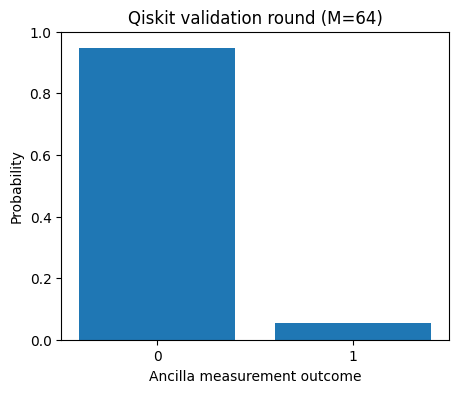

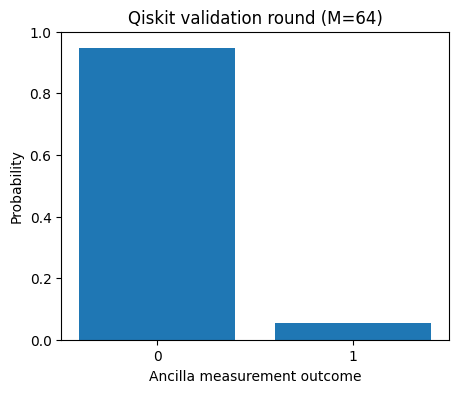

In [9]:
fig, ax = plt.subplots(figsize=(5, 4))
labels = sorted(shot_probs.keys())
values = [shot_probs[l] for l in labels]
ax.bar(labels, values, color="#1f77b4")
ax.set_xlabel("Ancilla measurement outcome")
ax.set_ylabel("Probability")
ax.set_ylim(0, 1)
ax.set_title(f"Qiskit validation round (M={final_M})")
fig.savefig("bayesian_qpe_qiskit_histogram.png", bbox_inches="tight", dpi=150)
fig


In [10]:
rep_circuit = ramsey_round_circuit(M_demo, beta_demo)
print(f"Representative round circuit (M={M_demo}):")
print("  Depth:", rep_circuit.depth())
print("  Gate counts:", dict(rep_circuit.count_ops()))

print(f"\nValidation circuit (M={final_M}, final round):")
print("  Depth:", validation_circuit.depth())
print("  Gate counts:", dict(validation_circuit.count_ops()))


Representative round circuit (M=1):
  Depth: 5
  Gate counts: {'h': 2, 'x': 1, 'cp': 1, 'p': 1, 'measure': 1}

Validation circuit (M=64, final round):
  Depth: 5
  Gate counts: {'h': 2, 'x': 1, 'cp': 1, 'p': 1, 'measure': 1}


In [11]:
print("CONVENTION NOTES")
print("- Bit order: Qiskit is natively little-endian (qubit 0 = rightmost bit / LSB). No reversal applied.")
print("- Global phase: normalized so the first nonzero amplitude (ascending bitstring order) is real positive.")
print("- Randomness: outcomes for the Bayesian loop are drawn from a SINGLE shared numpy RNG, seeded with")
print("  SEED, using the EXACT probability from Statevector simulation each round -- this keeps this")
print("  notebook's Bayesian trajectory identical to the CUDA-Q notebook's, since Aer's and CUDA-Q's own")
print("  internal PRNGs are different implementations and would NOT agree shot-for-shot on their own.")


CONVENTION NOTES
- Bit order: Qiskit is natively little-endian (qubit 0 = rightmost bit / LSB). No reversal applied.
- Global phase: normalized so the first nonzero amplitude (ascending bitstring order) is real positive.
- Randomness: outcomes for the Bayesian loop are drawn from a SINGLE shared numpy RNG, seeded with
  SEED, using the EXACT probability from Statevector simulation each round -- this keeps this
  notebook's Bayesian trajectory identical to the CUDA-Q notebook's, since Aer's and CUDA-Q's own
  internal PRNGs are different implementations and would NOT agree shot-for-shot on their own.


In [12]:
QISKIT_RESULT = {
    "theta_true": THETA_TRUE,
    "theta_est": THETA_EST,
    "abs_error_rad": error,
    "rounds": ROUNDS,
    "posterior_mean": THETA_EST,
    "posterior_resultant_length": float(
        np.hypot(np.sum(posterior * np.cos(theta_grid)), np.sum(posterior * np.sin(theta_grid)))
    ),
    "final_round_shot_probs": shot_probs,
}

with open("bayesian_qpe_qiskit_result.json", "w") as f:
    json.dump(QISKIT_RESULT, f, indent=2)

print(QISKIT_RESULT)


{'theta_true': 2.337344934270806, 'theta_est': 2.3449980191402853, 'abs_error_rad': 0.007653084869479354, 'rounds': 25, 'posterior_mean': 2.3449980191402853, 'posterior_resultant_length': 0.9404519628270744, 'final_round_shot_probs': {'1': 0.054375, '0': 0.945625}}


In [13]:
# --- Cross-framework diff check (run after BOTH notebooks have been executed at least once) ---
# import json
# with open("bayesian_qpe_qiskit_result.json") as f:
#     QISKIT_RESULT = json.load(f)
# with open("bayesian_qpe_cudaq_result.json") as f:
#     CUDAQ_RESULT = json.load(f)
#
# theta_delta = abs(((QISKIT_RESULT["theta_est"] - CUDAQ_RESULT["theta_est"] + np.pi) % (2*np.pi)) - np.pi)
# print("theta_est delta (rad):", theta_delta)
# assert theta_delta < 1e-3, "Qiskit and CUDA-Q Bayesian QPE estimates disagree!"
#
# hand_expected = 2 * np.pi * 0.372   # THETA_TRUE, the hand-computed sanity-check target
# print("Hand-computed / true theta for sanity check:", hand_expected)
